In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target
print("Samples, features:", X.shape)
print("target_names:", list(data.target_names), "(0 = malignant, 1 = benign)")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Samples, features: (569, 30)
target_names: [np.str_('malignant'), np.str_('benign')] (0 = malignant, 1 = benign)
Train: (426, 30) | Test: (143, 30)


All data  malignant=212 (37.3%)  benign=357 (62.7%)
Train     malignant=159 (37.3%)  benign=267 (62.7%)
Test      malignant=53 (37.1%)  benign=90 (62.9%)


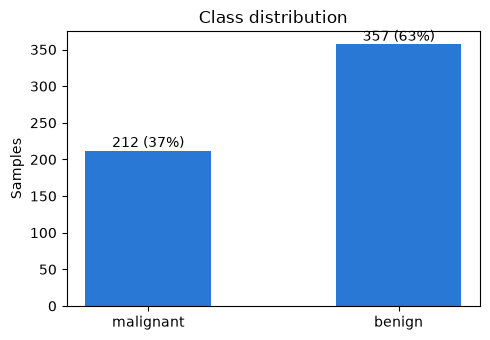

In [2]:
for name, labels in [("All data", y), ("Train", y_train), ("Test", y_test)]:
    counts = np.bincount(labels)
    print(f"{name:9s} malignant={counts[0]} ({counts[0]/len(labels):.1%})  "
          f"benign={counts[1]} ({counts[1]/len(labels):.1%})")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts = np.bincount(y)
ax.bar(["malignant", "benign"], counts, width=0.5, color="#2a78d6")
for i, c in enumerate(counts):
    ax.text(i, c + 5, f"{c} ({c/len(y):.0%})", ha="center")
ax.set_title("Class distribution")
ax.set_ylabel("Samples")
plt.tight_layout(); plt.show()

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Tree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
print("Train accuracy:", round(tree.score(X_train, y_train), 4))

Tree depth: 7 | leaves: 18
Train accuracy: 1.0


In [4]:
y_pred_tree = tree.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tree), 4))
print("F1-score :", round(f1_score(y_test, y_pred_tree), 4))
print()
print(classification_report(y_test, y_pred_tree,
                            target_names=data.target_names, digits=4))

Accuracy : 0.9231
Precision: 0.954
Recall   : 0.9222
F1-score : 0.9379

              precision    recall  f1-score   support

   malignant     0.8750    0.9245    0.8991        53
      benign     0.9540    0.9222    0.9379        90

    accuracy                         0.9231       143
   macro avg     0.9145    0.9234    0.9185       143
weighted avg     0.9247    0.9231    0.9235       143



In [5]:
from sklearn.model_selection import cross_val_score

results = []
for d in [2, 3, 4, 5, 6, 8, 10, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    pred = t.predict(X_test)
    cv = cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42),
                         X_train, y_train, cv=5).mean()
    results.append({
        "max_depth": str(d),
        "train_acc": round(t.score(X_train, y_train), 4),
        "test_acc": round(accuracy_score(y_test, pred), 4),
        "precision": round(precision_score(y_test, pred), 4),
        "recall": round(recall_score(y_test, pred), 4),
        "f1": round(f1_score(y_test, pred), 4),
        "cv_acc": round(cv, 4),
        "leaves": t.get_n_leaves(),
    })

depth_table = pd.DataFrame(results)
depth_table

,max_depth,train_acc,test_acc,precision,recall,f1,cv_acc,leaves
0,2,0.9577,0.9091,0.9639,0.8889,0.9249,0.9227,4
1,3,0.9765,0.9441,0.9457,0.9667,0.9560,0.9297,7
2,4,0.9883,0.9441,0.9556,0.9556,0.9556,0.9226,11
3,5,0.9953,0.9371,0.9551,0.9444,0.9497,0.9319,15
4,6,0.9977,0.9371,0.9551,0.9444,0.9497,0.9226,17
5,8,1.0000,0.9231,0.9540,0.9222,0.9379,0.9297,18
6,10,1.0000,0.9231,0.9540,0.9222,0.9379,0.9297,18
7,None,1.0000,0.9231,0.9540,0.9222,0.9379,0.9297,18


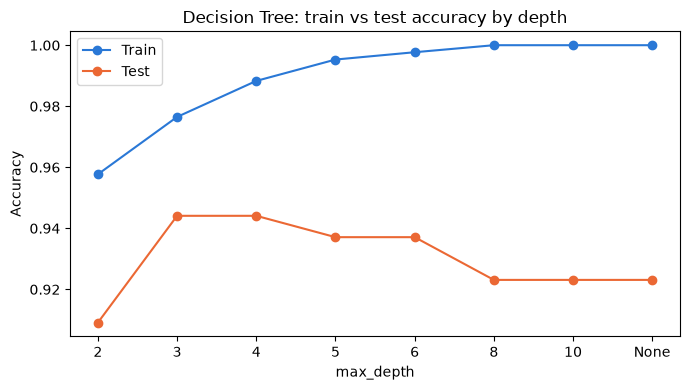

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depth_table["max_depth"], depth_table["train_acc"], marker="o", label="Train", color="#2a78d6")
ax.plot(depth_table["max_depth"], depth_table["test_acc"], marker="o", label="Test", color="#eb6834")
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.set_title("Decision Tree: train vs test accuracy by depth")
ax.legend()
plt.tight_layout(); plt.show()

In [7]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score :", round(f1_score(y_test, y_pred_rf), 4))
print()
print(classification_report(y_test, y_pred_rf, target_names=data.target_names, digits=4))

Accuracy : 0.958
Precision: 0.9565
Recall   : 0.9778
F1-score : 0.967

              precision    recall  f1-score   support

   malignant     0.9608    0.9245    0.9423        53
      benign     0.9565    0.9778    0.9670        90

    accuracy                         0.9580       143
   macro avg     0.9587    0.9512    0.9547       143
weighted avg     0.9581    0.9580    0.9579       143



In [8]:
#Comparing Models
models = {
    "Decision Tree (depth=None)": DecisionTreeClassifier(random_state=42),
    "Decision Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Random Forest (200 trees)": RandomForestClassifier(n_estimators=200, random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, y_train, cv=5)
    rows.append({
        "model": name,
        "train_acc": round(model.score(X_train, y_train), 4),
        "test_acc": round(accuracy_score(y_test, pred), 4),
        "precision": round(precision_score(y_test, pred), 4),
        "recall": round(recall_score(y_test, pred), 4),
        "f1": round(f1_score(y_test, pred), 4),
        "cv_mean": round(cv.mean(), 4),
        "cv_std": round(cv.std(), 4),
    })

pd.DataFrame(rows)

,model,train_acc,test_acc,precision,recall,f1,cv_mean,cv_std
0,Decision Tree (depth=None),1.0000,0.9231,0.9540,0.9222,0.9379,0.9297,0.0284
1,Decision Tree (depth=3),0.9765,0.9441,0.9457,0.9667,0.9560,0.9297,0.0284
2,Random Forest (100 trees),1.0000,0.9580,0.9565,0.9778,0.9670,0.9601,0.0206
3,Random Forest (200 trees),1.0000,0.9580,0.9565,0.9778,0.9670,0.9601,0.0206


In [9]:
def stability(make_model, n_splits=20):
    accs = []
    for seed in range(n_splits):
        a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
        accs.append(make_model(seed).fit(a, c).score(b, d))
    return np.mean(accs), np.std(accs), min(accs), max(accs)

for name, make in [
    ("Decision Tree (None)", lambda s: DecisionTreeClassifier(random_state=s)),
    ("Decision Tree (depth=3)", lambda s: DecisionTreeClassifier(max_depth=3, random_state=s)),
    ("Random Forest (200)", lambda s: RandomForestClassifier(n_estimators=200, random_state=s)),
]:
    m, s, lo, hi = stability(make)
    print(f"{name:25s} mean={m:.4f} std={s:.4f} min={lo:.4f} max={hi:.4f}")

Decision Tree (None)      mean=0.9297 std=0.0288 min=0.8601 max=0.9790
Decision Tree (depth=3)   mean=0.9287 std=0.0194 min=0.8811 max=0.9720
Random Forest (200)       mean=0.9633 std=0.0146 min=0.9441 max=0.9860


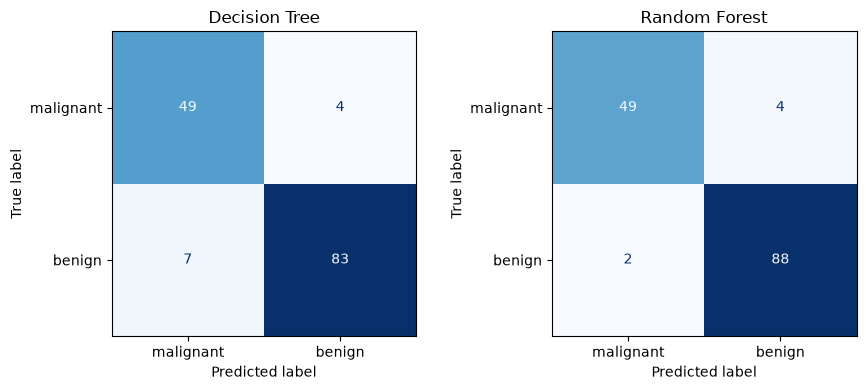

In [10]:
#confusion matrices for both models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, pred) in zip(axes, [("Decision Tree", y_pred_tree), ("Random Forest", y_pred_rf)]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [11]:
#count each error type
for name, pred in [("Decision Tree", y_pred_tree), ("Random Forest", y_pred_rf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(name)
    print(f"  Malignant found: {tn}/{tn+fp}   MISSED malignant (called benign): {fp}")
    print(f"  Benign found:    {tp}/{tp+fn}   Benign flagged as malignant:     {fn}")

Decision Tree
  Malignant found: 49/53   MISSED malignant (called benign): 4
  Benign found:    83/90   Benign flagged as malignant:     7
Random Forest
  Malignant found: 49/53   MISSED malignant (called benign): 4
  Benign found:    88/90   Benign flagged as malignant:     2


In [12]:
from sklearn.tree import export_text

small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(export_text(small_tree, feature_names=list(data.feature_names)))

importances = pd.Series(rf.feature_importances_, index=data.feature_names)
print(importances.sort_values(ascending=False).head(5).round(4))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0

worst perimeter         0.1457
worst area              0.1368
worst concave points    0.1072
mean concave points     0.1039
worst radius            0.0761
dtype: float64


In [14]:
from sklearn.metrics import recall_score

for name, model in [("Decision Tree (None)", DecisionTreeClassifier(random_state=42)),
                    ("Decision Tree (depth=3)", DecisionTreeClassifier(max_depth=3, random_state=42)),
                    ("Random Forest (200)", RandomForestClassifier(n_estimators=200, random_state=42))]:
    pred = model.fit(X_train, y_train).predict(X_test)
    print(f"{name:25s} malignant recall={recall_score(y_test, pred, pos_label=0):.4f}  "
          f"accuracy={accuracy_score(y_test, pred):.4f}")

Decision Tree (None)      malignant recall=0.9245  accuracy=0.9231
Decision Tree (depth=3)   malignant recall=0.9057  accuracy=0.9441
Random Forest (200)       malignant recall=0.9245  accuracy=0.9580
